# Random forest · Model building (Issue #13, bagging family)

## Where this notebook sits
```
03_clean ─► 04_feature_engineering ─► 05_encode_scale ─► model_ready_{fit,valid,test}.parquet
06_ml_algorithms_exploration (#11) ─► shortlist (#12): LightGBM, LogReg, Random forest
model_building/lightgbm.ipynb  (#13, boosting)   ─┐
model_building/randomforest.ipynb ◄── this one   ─┴─► Task #4 candidate model choice ─► #14 tuning
```

**Input:** `data/processed/model_ready_{fit,valid,test}.parquet` (run `run_pipeline.py` first).

**Why `model_ready` and not `features_train`.** scikit-learn's `RandomForestClassifier` cannot take
`NaN` or pandas categoricals, unlike LightGBM. The `model_ready` files from notebook 05 are already
imputed, scaled and one-hot encoded, which is exactly what this model needs. Scaling is harmless for
a tree model — it splits on order, not distance — so nothing is lost by using the same files the
logistic-regression baseline uses.

## Read this first: the notebook in two minutes

**The problem.** ~30% of applicants are **thin-file** (no credit-bureau records). A model predicts each
applicant's **probability of default (PD)**; at +$2,000 per repaid loan and −$8,000 per default, the
break-even cutoff is 20%.

**What a random forest is.** Many deep decision trees, each grown on a random subset of rows and
choosing from a random subset of features at every split. The prediction is the average of all the
trees. Boosting (LightGBM) builds trees *in sequence*, each correcting the last; bagging (random
forest) builds them *independently* and averages. Averaging independent trees reduces variance;
correcting in sequence reduces bias. They fail in different ways, which is why the shortlist includes
both.

**What this notebook does.**
1. Reproduces the exploration-notebook random forest as a reference point.
2. Tunes it with random search, judged on the tune weeks (68–79) only.
3. Retrains on weeks 0–79 and scores weeks 80–91 **once**.
4. Applies the same two fixes the LightGBM notebook found necessary — per-segment calibration and
   recency weighting — and reports whether they help here too.
5. Saves settings, predictions and the comparison row for Task #4.

**Expected result, stated up front.** A random forest should rank slightly worse than boosting on
tabular credit data, and its probabilities should be noticeably worse: averaging many votes pulls
predictions toward the middle of the range, so a forest tends to be over-confident near the base rate
and under-confident at the extremes. Since the 20% cutoff and the profit calculation both depend on
the probability being honest, that matters more here than the AUC does.

## 1. Setup

In [1]:
# Libraries, paths and the constants used everywhere (time split, profit rules).

from pathlib import Path
import gc
import json
import os
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.calibration import calibration_curve
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, brier_score_loss, f1_score,
                             log_loss, roc_auc_score)

warnings.filterwarnings("ignore", category=UserWarning)

ROOT = Path.cwd().parent.parent          # notebooks/model_building -> repo root
PROCESSED = ROOT / "data" / "processed"
ART = Path.cwd() / "artifacts"
ART.mkdir(exist_ok=True)

SEED = 42
N_THREADS = os.cpu_count()


def mem():
    # Current resident memory in GB. This notebook runs close to the 8 GB limit of a
    # 2-core Codespace, so several cells report it.
    with open("/proc/self/statm") as f:
        return int(f.read().split()[1]) * os.sysconf("SC_PAGE_SIZE") / 1e9

# Time split (identical to notebooks 04-07 and lightgbm.ipynb):
#   weeks  0-67 -> train   (models learn here)
#   weeks 68-79 -> tune    (hyper-parameter choice, calibration)
#   weeks 80-91 -> valid   (scored ONCE per final model)
#   weeks 92-107 = test set, labels hidden (solution.csv is never opened)
TUNE_START_WEEK = 68
VALID_START_WEEK = 80

# Challenge economics: +$2,000 per repaid approved loan, -$8,000 per defaulted approved loan.
GAIN, LOSS = 2_000, -8_000
CUTOFF = 0.20                            # break-even: 2000 - 10000p = 0  ->  p = 0.2

print(f"{N_THREADS} threads available | memory in use: {mem():.2f} GB")

2 threads available | memory in use: 0.26 GB


## 2. Load data and build the splits

`thin_file` is **not** a feature (same as notebook 07 and lightgbm.ipynb): everyone is scored by the
same rules. It is kept to report metrics per segment and, in §7, to calibrate per segment.

In [2]:
# Load the model-ready files and split the fit rows by week into train / tune.

fit_df = pd.read_parquet(PROCESSED / "model_ready_fit.parquet")      # weeks 0-79
val_df = pd.read_parquet(PROCESSED / "model_ready_valid.parquet")    # weeks 80-91

NOT_FEATURES = ["case_id", "target", "WEEK_NUM", "thin_file"]
FEATURES = [c for c in fit_df.columns if c not in NOT_FEATURES]

# float32 instead of float64. scikit-learn's trees cast to float32 internally anyway, so this
# halves the memory held here AND avoids a hidden full-size copy at every .fit() call.
# With ~870k rows x ~106 features that is the difference between ~740 MB and ~370 MB per frame.
X_fit = fit_df[FEATURES].astype(np.float32)
X_val = val_df[FEATURES].astype(np.float32)
y_fit, y_val = fit_df["target"].to_numpy(), val_df["target"].to_numpy()
thin_fit, thin_val = fit_df["thin_file"].to_numpy(), val_df["thin_file"].to_numpy()
week_fit, week_val = fit_df["WEEK_NUM"].to_numpy(), val_df["WEEK_NUM"].to_numpy()
val_case_id = val_df["case_id"].to_numpy()          # kept for the predictions file in section 12

# The source frames are no longer needed; everything above is extracted.
del fit_df, val_df
gc.collect()

# Within the fit window: weeks 0-67 train, weeks 68-79 tune.
TR = week_fit < TUNE_START_WEEK
TU = ~TR

print(f"{len(FEATURES)} features (all numeric, imputed + scaled + one-hot encoded by notebook 05)")
print(f"memory in use: {mem():.2f} GB")
pd.DataFrame({
    "weeks": ["0-67", "68-79", "80-91"],
    "rows": [TR.sum(), TU.sum(), len(X_val)],
    "default rate %": [y_fit[TR].mean() * 100, y_fit[TU].mean() * 100, y_val.mean() * 100],
    "thin-file default rate %": [
        y_fit[TR & (thin_fit == 1)].mean() * 100,
        y_fit[TU & (thin_fit == 1)].mean() * 100,
        y_val[thin_val == 1].mean() * 100,
    ],
}, index=["train", "tune", "valid"]).round(2)

106 features (all numeric, imputed + scaled + one-hot encoded by notebook 05)
memory in use: 0.83 GB


,weeks,rows,default rate %,thin-file default rate %
train,0-67,739183,19.72,27.45
tune,68-79,130376,17.91,21.22
valid,80-91,130441,17.36,19.81


Thin-file default risk falls across the three windows. Any model trained on the older weeks will
therefore **over-estimate** thin-file risk on the later weeks — the drift Krish quantified in notebook 07
(10.78 pp narrowing, 95% CI 10.28–11.28). Keep it in mind when reading §6 onward.

## 3. One evaluation function for every model

Copied unchanged from `lightgbm.ipynb` so the two notebooks' rows are directly comparable:

- **Ranking:** AUC overall / thin-file / established (higher is better)
- **Probability quality:** LogLoss and Brier (lower is better), plus *predicted minus actual* default
  rate per segment (0 = honest)
- **Task #3 metrics at the 20% cutoff:** accuracy and F1 (class 1 = default, so a "positive" is a
  decline). Approving everyone already scores ~83% accuracy, so accuracy alone is misleading.
- **Decision quality at the 20% cutoff:** approval rate, default rate among approved, profit, and the
  **inclusion gap** (approval rate among repayers: established minus thin-file)
- **Gap at 70% approval:** Krish's notebook-07 setting, for a like-for-like comparison

In [3]:
# evaluate(): turns predicted default probabilities into every metric the challenge uses.
# Identical to lightgbm.ipynb so the results tables can be concatenated.

def evaluate(y, p, thin, cutoff=CUTOFF):
    y, p, thin = np.asarray(y), np.asarray(p), np.asarray(thin) == 1
    est = ~thin
    decline = p >= cutoff
    approve = ~decline
    repaid = y == 0

    def approval_gap(appr):
        return (appr[repaid & est].mean() - appr[repaid & thin].mean()) * 100

    approve_70 = p < np.quantile(p, 0.70)
    return {
        "AUC": roc_auc_score(y, p),
        "AUC thin": roc_auc_score(y[thin], p[thin]),
        "AUC est": roc_auc_score(y[est], p[est]),
        "LogLoss": log_loss(y, p),
        "LogLoss thin": log_loss(y[thin], p[thin]),
        "Brier": brier_score_loss(y, p),
        "Pred-actual thin pp": (p[thin].mean() - y[thin].mean()) * 100,
        "Pred-actual est pp": (p[est].mean() - y[est].mean()) * 100,
        "Accuracy@20%": accuracy_score(y, decline),
        "F1@20%": f1_score(y, decline),
        "Approval %": approve.mean() * 100,
        "Default % approved": y[approve].mean() * 100,
        "Profit $M": (GAIN * (approve & repaid).sum() + LOSS * (approve & ~repaid).sum()) / 1e6,
        "Approved repayers est %": approve[repaid & est].mean() * 100,
        "Approved repayers thin %": approve[repaid & thin].mean() * 100,
        "Gap@20% pp": approval_gap(approve),
        "Gap@70% approval pp": approval_gap(approve_70),
    }


results = {}   # model name -> metrics on weeks 80-91

## 4. Reference points

1. **Logistic regression** on the same files (team baseline, notebook 05) — the model this one must beat.
2. **Random forest with the exploration-notebook settings** (200 trees, `min_samples_leaf=50`,
   `max_samples=0.3`), so this notebook is consistent with Issue #11.

Both are trained on weeks 0–79 and scored on weeks 80–91.

In [4]:
# Two reference points: the logistic-regression baseline and the untuned forest from notebook 06.

t = time.time()
logreg = LogisticRegression(max_iter=1000).fit(X_fit, y_fit)
p_logreg = logreg.predict_proba(X_val)[:, 1]
results["LogReg (05 baseline)"] = evaluate(y_val, p_logreg, thin_val)
print(f"logistic regression trained in {time.time() - t:.0f}s")

t = time.time()
rf_ref = RandomForestClassifier(
    n_estimators=200, min_samples_leaf=50, max_samples=0.3,
    n_jobs=N_THREADS, random_state=SEED,
).fit(X_fit, y_fit)
p_ref = rf_ref.predict_proba(X_val)[:, 1]
results["RandomForest untuned (#11 settings)"] = evaluate(y_val, p_ref, thin_val)
print(f"untuned random forest trained in {time.time() - t:.0f}s")

# Free it: only its metrics are needed from here on. Forests are large, and §8-§9
# keep several in memory at once.
del rf_ref, logreg
gc.collect()
print(f"memory in use: {mem():.2f} GB")

pd.DataFrame(results).T[["AUC", "AUC thin", "AUC est", "LogLoss", "Brier",
                         "Pred-actual thin pp", "Profit $M", "Gap@20% pp"]].round(4)

logistic regression trained in 9s
untuned random forest trained in 217s
memory in use: 0.95 GB


,AUC,AUC thin,AUC est,LogLoss,Brier,Pred-actual thin pp,Profit $M,Gap@20% pp
LogReg (05 baseline),0.7597,0.7082,0.7856,0.3980,0.1241,6.4004,92.190,37.8408
RandomForest untuned (#11 settings),0.7657,0.7066,0.7920,0.3941,0.1230,6.0121,93.928,34.2832


## 5. Tune the forest

**Method: random search, judged on the tune weeks (68–79) only.** A random forest has no early
stopping — adding trees cannot make it overfit, it only makes the average smoother — so the tree count
is fixed and the search covers the settings that control *how deep each tree grows* and *how much
randomness it uses*.

| Setting | What it controls | Range searched |
|---|---|---|
| `min_samples_leaf` | smallest group a leaf may contain (bigger = smoother) | 200–3000 (log scale) |
| `max_features` | how many features each split may choose from | sqrt, log2, 0.3 |
| `max_depth` | hard cap on tree depth | 8, 10, 12, 14 |
| `max_samples` | share of rows each tree is grown on | 0.2–0.4 |

`n_estimators` is held at 60 during the search to keep it affordable, then raised to 200 for the final model.

**Why depth is capped.** An earlier run of this notebook allowed `max_depth=None` (fully grown trees) with
`max_samples` up to 0.8. On this 2-core machine a single such trial took 22 minutes, against ~3 minutes for
a capped one, which put a 12-trial search beyond four hours. The cap is defensible on evidence, not just
convenience: `lightgbm.ipynb` searched the same kind of space and found **28 of 30 settings tied within
0.0003 LogLoss**, with the *simplest* settings winning (15 leaves, ~2,000 applicants minimum per leaf). On
this data the signal is simple, so shallow heavily-regularised trees are where the answer lives. This
should be stated as a methods note in the write-up.
Each candidate trains on weeks 0–67 and is scored on weeks 68–79 by **LogLoss**, the same criterion
LightGBM used. Among near-ties (within 0.0003) the simplest settings win.

In [5]:
# Try random forest settings; score each on the tune weeks only.

N_RF_TRIALS = 6
TIE_TOLERANCE = 0.0003
SEARCH_TREES = 60
rng = np.random.default_rng(SEED)

X_tr, y_tr = X_fit[TR], y_fit[TR]
X_tu, y_tu = X_fit[TU], y_fit[TU]
thin_tu = thin_fit[TU]


# Pick by index, not by value: rng.choice on a mixed list would coerce 0.5 to the
# string "0.5", which sklearn rejects.
MAX_FEATURES_GRID = ["sqrt", "log2", 0.3]
MAX_DEPTH_GRID = [8, 10, 12, 14]


def sample_rf():
    return {
        "min_samples_leaf": int(np.exp(rng.uniform(np.log(200), np.log(3000)))),
        "max_features": MAX_FEATURES_GRID[rng.choice(len(MAX_FEATURES_GRID), p=[0.5, 0.25, 0.25])],
        "max_depth": MAX_DEPTH_GRID[rng.choice(len(MAX_DEPTH_GRID))],
        "max_samples": round(float(rng.uniform(0.2, 0.4)), 2),
    }


trial_params, rows, t0 = [], [], time.time()
for i in range(N_RF_TRIALS):
    hp = sample_rf()
    m = RandomForestClassifier(n_estimators=SEARCH_TREES, n_jobs=N_THREADS,
                               random_state=SEED, **hp).fit(X_tr, y_tr)
    p_tu = m.predict_proba(X_tu)[:, 1]
    p_tr = m.predict_proba(X_tr.iloc[:100_000])[:, 1]      # sample, only for the overfit gap
    trial_params.append(hp)                                 # keep the real values for §5b
    rows.append({
        "trial": i,
        **{k: str(v) for k, v in hp.items()},                # strings are for display only
        "tune_logloss": log_loss(y_tu, p_tu),
        "tune_auc": roc_auc_score(y_tu, p_tu),
        "tune_auc_thin": roc_auc_score(y_tu[thin_tu == 1], p_tu[thin_tu == 1]),
        "overfit_gap": log_loss(y_tu, p_tu) - log_loss(y_tr[:100_000], p_tr),
    })
    print(f"  trial {i + 1}/{N_RF_TRIALS}: tune LogLoss {rows[-1]['tune_logloss']:.4f}"
          f"  ({(time.time() - t0) / 60:.1f} min elapsed)")

rf_tuning = pd.DataFrame(rows).sort_values("tune_logloss").reset_index(drop=True)
print(f"\n{N_RF_TRIALS} random forest trials in {(time.time() - t0) / 60:.1f} min")
rf_tuning.round(4)

  trial 1/6: tune LogLoss 0.4029  (0.6 min elapsed)
  trial 2/6: tune LogLoss 0.3969  (2.7 min elapsed)
  trial 3/6: tune LogLoss 0.4042  (3.2 min elapsed)
  trial 4/6: tune LogLoss 0.4096  (3.5 min elapsed)
  trial 5/6: tune LogLoss 0.4038  (3.9 min elapsed)
  trial 6/6: tune LogLoss 0.4085  (4.3 min elapsed)

6 random forest trials in 4.3 min


,trial,min_samples_leaf,max_features,max_depth,max_samples,tune_logloss,tune_auc,tune_auc_thin,overfit_gap
0,1,258,0.3,14,0.35,0.3969,0.7721,0.7148,-0.0119
1,0,1626,sqrt,10,0.34,0.4029,0.7658,0.7148,-0.0161
2,4,664,sqrt,8,0.21,0.4038,0.7641,0.7139,-0.0160
3,2,1680,sqrt,14,0.27,0.4042,0.7645,0.7145,-0.0161
4,5,1881,log2,12,0.35,0.4085,0.7600,0.7126,-0.0163
5,3,2460,log2,10,0.36,0.4096,0.7578,0.7081,-0.0168


In [6]:
# Pick the winner: best tune LogLoss, simplest settings among near-ties.

ties = rf_tuning[rf_tuning["tune_logloss"] <= rf_tuning["tune_logloss"].min() + TIE_TOLERANCE]
# "Simplest" = largest minimum leaf size (smoothest trees) among the near-ties.
winner = ties.loc[ties["min_samples_leaf"].astype(int).idxmax()]
RF_PARAMS = trial_params[int(winner["trial"])]     # the real values, not the display strings
FINAL_TREES = 200

print(f"{len(ties)} of {N_RF_TRIALS} settings tied within {TIE_TOLERANCE}; chose the simplest:")
print(json.dumps({k: str(v) for k, v in RF_PARAMS.items()}, indent=2))
print(f"tune LogLoss {winner['tune_logloss']:.4f} | final model will use {FINAL_TREES} trees")

1 of 6 settings tied within 0.0003; chose the simplest:
{
  "min_samples_leaf": "258",
  "max_features": "0.3",
  "max_depth": "14",
  "max_samples": "0.35"
}
tune LogLoss 0.3969 | final model will use 200 trees


### Does adding trees still help?

Unlike boosting, more trees cannot overfit a forest — they only smooth the average. The useful question
is where that smoothing stops paying for itself, since every tree costs time at scoring. This trains the
chosen settings once and scores the tune weeks at increasing tree counts.

memory in use: 1.41 GB


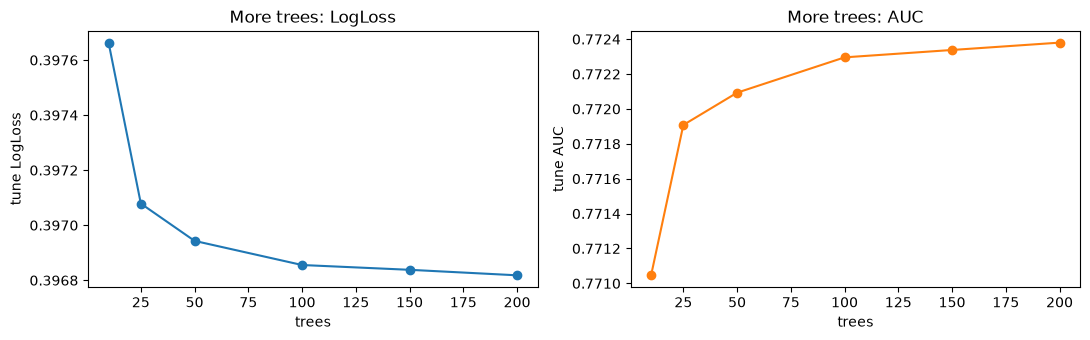

,trees,tune_logloss,tune_auc
0,10,0.3977,0.7710
1,25,0.3971,0.7719
2,50,0.3969,0.7721
3,100,0.3969,0.7723
4,150,0.3968,0.7723
5,200,0.3968,0.7724


In [7]:
# How tune LogLoss improves as trees are added (chosen settings, weeks 0-67 -> 68-79).

rf_curve = RandomForestClassifier(n_estimators=FINAL_TREES, n_jobs=N_THREADS,
                                  random_state=SEED, **RF_PARAMS).fit(X_tr, y_tr)

# Average the trees' probabilities one at a time, recording the running mean at each checkpoint.
# (Stacking all FINAL_TREES predictions at once would allocate trees x rows floats - hundreds of MB.)
checkpoints = [c for c in [10, 25, 50, 100, 150, 200, 300, FINAL_TREES] if c <= FINAL_TREES]
X_tu_vals = X_tu.values
running, curve_rows = np.zeros(len(X_tu)), []
for k, est in enumerate(rf_curve.estimators_, start=1):
    running += est.predict_proba(X_tu_vals)[:, 1]
    if k in checkpoints:
        p_k = running / k
        curve_rows.append({"trees": k, "tune_logloss": log_loss(y_tu, p_k),
                           "tune_auc": roc_auc_score(y_tu, p_k)})
curve = pd.DataFrame(curve_rows)

# Section 8 needs this model's predictions on the tune and validation weeks, but not the
# model itself. Score now and drop the forest - it is ~0.5 GB.
p_early_tune = rf_curve.predict_proba(X_tu)[:, 1]
p_early_val = rf_curve.predict_proba(X_val)[:, 1]

del X_tu_vals, running, rf_curve
gc.collect()
print(f"memory in use: {mem():.2f} GB")

fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].plot(curve["trees"], curve["tune_logloss"], marker="o")
ax[0].set(xlabel="trees", ylabel="tune LogLoss", title="More trees: LogLoss")
ax[1].plot(curve["trees"], curve["tune_auc"], marker="o", color="tab:orange")
ax[1].set(xlabel="trees", ylabel="tune AUC", title="More trees: AUC")
plt.tight_layout(); plt.show()
curve.round(4)

## 6. Final model: retrain on weeks 0–79 and score weeks 80–91 once

This is the first time the validation weeks are used for this model.

In [8]:
# Retrain the chosen settings on all fit weeks and score the untouched validation weeks.

t = time.time()
rf_final = RandomForestClassifier(n_estimators=FINAL_TREES, n_jobs=N_THREADS,
                                  random_state=SEED, **RF_PARAMS).fit(X_fit, y_fit)
print(f"final forest trained in {time.time() - t:.0f}s")

p_rf = rf_final.predict_proba(X_val)[:, 1]
results["RandomForest tuned"] = evaluate(y_val, p_rf, thin_val)

pd.DataFrame(results).T[["AUC", "AUC thin", "AUC est", "LogLoss", "LogLoss thin", "Brier",
                         "Pred-actual thin pp", "Pred-actual est pp"]].round(4)

final forest trained in 522s


,AUC,AUC thin,AUC est,LogLoss,LogLoss thin,Brier,Pred-actual thin pp,Pred-actual est pp
LogReg (05 baseline),0.7597,0.7082,0.7856,0.3980,0.4673,0.1241,6.4004,-0.0527
RandomForest untuned (#11 settings),0.7657,0.7066,0.7920,0.3941,0.4653,0.1230,6.0121,0.1740
RandomForest tuned,0.7679,0.7071,0.7941,0.3928,0.4648,0.1228,5.9786,0.1342


## 7. Probability accuracy per segment (reliability curves)

If the probabilities are honest, applicants given a 20% predicted risk should default about 20% of the
time — points on the diagonal. Points **below** the diagonal mean risk is **over-estimated**: those
applicants are safer than the model thinks.

Two separate problems are expected here, and they should be read apart:
- **Thin-file over-prediction from drift**, the same issue LightGBM had.
- **Forest compression**, specific to bagging: averaging many votes pulls every prediction toward the
  middle, so the range of predicted probabilities is narrower than reality. Watch whether the curve is
  flatter than the diagonal rather than merely shifted off it.

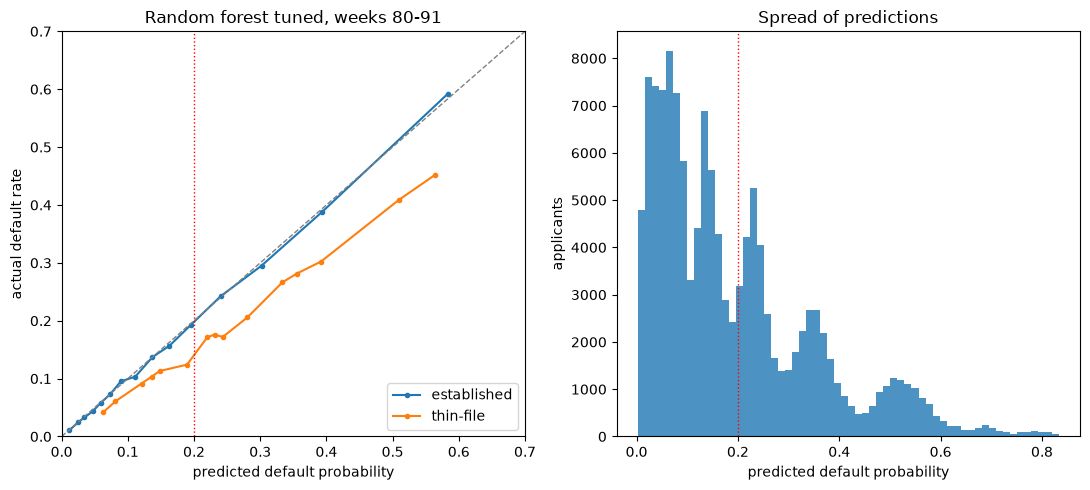

predicted PD range: 0.002 to 0.833  (actual default rate 0.174)
share of applicants predicted above the 20% cutoff: 39.4%


In [9]:
# Predicted vs actual default rate per segment, plus the spread of the predictions.

def reliability_plot(ax, p, title):
    for seg, label in [(0, "established"), (1, "thin-file")]:
        m = thin_val == seg
        frac, mean_pred = calibration_curve(y_val[m], p[m], n_bins=15, strategy="quantile")
        ax.plot(mean_pred, frac, marker="o", ms=3, label=label)
    ax.plot([0, 0.7], [0, 0.7], color="grey", ls="--", lw=1)
    ax.axvline(CUTOFF, color="red", ls=":", lw=1)
    ax.set(xlabel="predicted default probability", ylabel="actual default rate",
           title=title, xlim=(0, 0.7), ylim=(0, 0.7))
    ax.legend()


fig, axes = plt.subplots(1, 2, figsize=(11, 5))
reliability_plot(axes[0], p_rf, "Random forest tuned, weeks 80-91")
axes[1].hist(p_rf, bins=60, alpha=0.8)
axes[1].axvline(CUTOFF, color="red", ls=":", lw=1)
axes[1].set(xlabel="predicted default probability", ylabel="applicants",
            title="Spread of predictions")
plt.tight_layout(); plt.show()

print(f"predicted PD range: {p_rf.min():.3f} to {p_rf.max():.3f}  (actual default rate {y_val.mean():.3f})")
print(f"share of applicants predicted above the 20% cutoff: {(p_rf >= CUTOFF).mean():.1%}")

## 8. Fix 1: per-segment calibration

The same correction the LightGBM notebook used, applied here:

- Train the chosen settings on weeks 0–67 only, so weeks 68–79 are unseen.
- On weeks 68–79, fit a **Platt scaling** (a 2-parameter logistic correction of the model's log-odds)
  separately for thin-file and established applicants.
- Apply that correction to the same model's predictions on weeks 80–91.

Two parameters per segment cannot overfit 160k rows. The ranking of applicants within each segment is
unchanged; only the probability *level* moves.

**Fairness note:** this uses `thin_file` when *converting* scores to probabilities, not as a model
feature. It is the "calibrated segment policy" in technical report §12 and should be discussed with the
team before adoption.

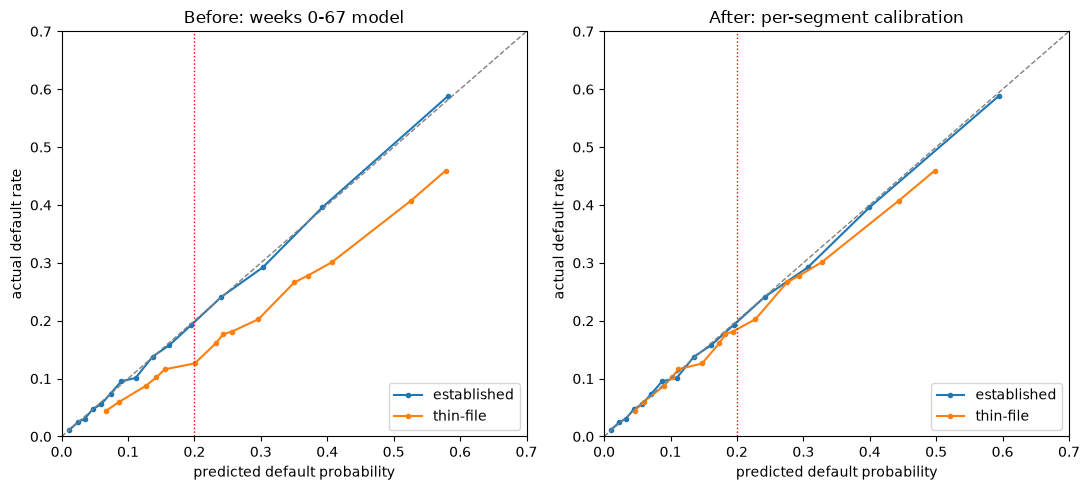

,AUC,AUC thin,LogLoss,Brier,Pred-actual thin pp,Profit $M,Gap@20% pp
RandomForest weeks 0-67 (uncalibrated),0.7666,0.7075,0.3942,0.1233,7.1300,93.852,36.8402
RandomForest + segment calibration,0.7706,0.7075,0.3898,0.1216,1.3516,96.972,12.2590


In [10]:
# Fix 1: learn a probability correction per segment on weeks 68-79, apply it to weeks 80-91.

def logit(p):
    p = np.clip(p, 1e-6, 1 - 1e-6)
    return np.log(p / (1 - p)).reshape(-1, 1)


def fit_segment_calibration(p, y, thin):
    return {seg: LogisticRegression(C=1e6).fit(logit(p[thin == seg]), y[thin == seg])
            for seg in (0, 1)}


def apply_segment_calibration(cal, p, thin):
    out = p.copy()
    for seg, model in cal.items():
        m = thin == seg
        out[m] = model.predict_proba(logit(p[m]))[:, 1]
    return out


# p_early_tune / p_early_val come from the weeks 0-67 model scored in section 5b, so weeks
# 68-79 are clean for fitting the correction.
calibrators = fit_segment_calibration(p_early_tune, y_fit[TU], thin_fit[TU])
p_rf_cal = apply_segment_calibration(calibrators, p_early_val, thin_val)

results["RandomForest weeks 0-67 (uncalibrated)"] = evaluate(y_val, p_early_val, thin_val)
results["RandomForest + segment calibration"] = evaluate(y_val, p_rf_cal, thin_val)

fig, axes = plt.subplots(1, 2, figsize=(11, 5))
reliability_plot(axes[0], p_early_val, "Before: weeks 0-67 model")
reliability_plot(axes[1], p_rf_cal, "After: per-segment calibration")
plt.tight_layout(); plt.show()

pd.DataFrame(results).T.loc[
    ["RandomForest weeks 0-67 (uncalibrated)", "RandomForest + segment calibration"],
    ["AUC", "AUC thin", "LogLoss", "Brier", "Pred-actual thin pp", "Profit $M", "Gap@20% pp"]
].round(4)

## 9. Fix 2: recency weighting

> **Memory note.** Each candidate forest here is scored and then discarded with `del` + `gc.collect()`.
> Holding all four at once, on top of the forests from §4–§8, is enough to crash the kernel on an
> 8 GB machine.

Instead of correcting afterwards, let the forest **learn more from recent weeks** during training. Each
row gets weight `0.5 ** ((last_week - week) / half_life)`: a row `half_life` weeks old counts half as
much as the newest row. `WEEK_NUM` is used only as a *weight*, never as a feature — test weeks 92+ lie
outside the training range, so a model that split on week number could not generalise to them.

The half-life is chosen on the tune weeks, from the same fixed set LightGBM used, so validation stays
untouched. LightGBM chose 13 weeks, the shortest offered.

In [11]:
# Fix 2, part 1: choose how strongly to favour recent weeks, using the tune weeks only.

def recency_weights(weeks, last_week, half_life):
    return np.ones(len(weeks)) if half_life is None else 0.5 ** ((last_week - weeks) / half_life)


# Each candidate forest is scored and then discarded. Keeping all four in memory
# alongside the forests from §4-§8 is enough to exhaust an 8 GB machine.

hl_scores = {}
for hl in [None, 52, 26, 13]:
    w = recency_weights(week_fit[TR], TUNE_START_WEEK - 1, hl)
    m = RandomForestClassifier(n_estimators=SEARCH_TREES, n_jobs=N_THREADS,
                               random_state=SEED, **RF_PARAMS).fit(X_tr, y_tr, sample_weight=w)
    p_tu = m.predict_proba(X_tu)[:, 1]
    hl_scores[str(hl)] = {"tune_logloss": log_loss(y_fit[TU], p_tu),
                          "tune_auc": roc_auc_score(y_fit[TU], p_tu)}
    del m                       # drop the forest, keep only its scores
    gc.collect()
    print(f"  half-life {str(hl):>4}: tune LogLoss {hl_scores[str(hl)]['tune_logloss']:.4f}")

hl_table = pd.DataFrame(hl_scores).T
BEST_HL = hl_table["tune_logloss"].idxmin()
print()
print(f"chosen half-life: {BEST_HL} weeks" if BEST_HL != "None" else "chosen: no recency weighting")
hl_table.round(4)

  half-life None: tune LogLoss 0.3969
  half-life   52: tune LogLoss 0.3964
  half-life   26: tune LogLoss 0.3960
  half-life   13: tune LogLoss 0.3955

chosen half-life: 13 weeks


,tune_logloss,tune_auc
None,0.3969,0.7723
52,0.3964,0.7728
26,0.3960,0.7733
13,0.3955,0.7736


In [12]:
# Fix 2, part 2: the recency-weighted forest on its own, and combined with Fix 1.

hl = None if BEST_HL == "None" else int(BEST_HL)

# (a) weighted model retrained on weeks 0-79, weights relative to week 79
w_fit = recency_weights(week_fit, VALID_START_WEEK - 1, hl)
rf_recency = RandomForestClassifier(n_estimators=FINAL_TREES, n_jobs=N_THREADS,
                                    random_state=SEED, **RF_PARAMS).fit(X_fit, y_fit, sample_weight=w_fit)
p_rf_rec = rf_recency.predict_proba(X_val)[:, 1]
results["RandomForest + recency weighting"] = evaluate(y_val, p_rf_rec, thin_val)

# (b) both fixes: weighted model trained on 0-67 only, then calibrated per segment on 68-79.
# Refit here rather than holding it from §9a - same seed and settings, so it is the same model.
del rf_recency
gc.collect()
m_rec_early = RandomForestClassifier(n_estimators=SEARCH_TREES, n_jobs=N_THREADS, random_state=SEED,
                                     **RF_PARAMS).fit(X_tr, y_tr,
                                     sample_weight=recency_weights(week_fit[TR], TUNE_START_WEEK - 1, hl))
cal_rec = fit_segment_calibration(m_rec_early.predict_proba(X_tu)[:, 1], y_fit[TU], thin_fit[TU])
p_rf_rec_cal = apply_segment_calibration(cal_rec, m_rec_early.predict_proba(X_val)[:, 1], thin_val)
results["RandomForest + recency + calibration"] = evaluate(y_val, p_rf_rec_cal, thin_val)
del m_rec_early
gc.collect()

pd.DataFrame(results).T.loc[
    ["RandomForest tuned", "RandomForest + recency weighting",
     "RandomForest + segment calibration", "RandomForest + recency + calibration"],
    ["AUC", "AUC thin", "LogLoss", "Brier", "Pred-actual thin pp", "Profit $M", "Gap@20% pp"]
].round(4)

,AUC,AUC thin,LogLoss,Brier,Pred-actual thin pp,Profit $M,Gap@20% pp
RandomForest tuned,0.7679,0.7071,0.3928,0.1228,5.9786,94.134,35.9057
RandomForest + recency weighting,0.7697,0.7075,0.3908,0.1219,2.9363,96.268,20.4967
RandomForest + segment calibration,0.7706,0.7075,0.3898,0.1216,1.3516,96.972,12.2590
RandomForest + recency + calibration,0.7700,0.7071,0.3903,0.1218,1.3833,96.824,12.3471


## 10. Results: every model on weeks 80–91

Probability quality and decision quality side by side. **Profit** and **inclusion gap** use the
challenge's 20% break-even cutoff.

In [13]:
# Probability quality for every model in this notebook.

res = pd.DataFrame(results).T
res.to_csv(ART / "results_randomforest_valid_weeks_80_91.csv")

res[["AUC", "AUC thin", "AUC est", "LogLoss", "LogLoss thin", "Brier",
     "Pred-actual thin pp", "Pred-actual est pp"]].round(4)

,AUC,AUC thin,AUC est,LogLoss,LogLoss thin,Brier,Pred-actual thin pp,Pred-actual est pp
LogReg (05 baseline),0.7597,0.7082,0.7856,0.3980,0.4673,0.1241,6.4004,-0.0527
RandomForest untuned (#11 settings),0.7657,0.7066,0.7920,0.3941,0.4653,0.1230,6.0121,0.1740
RandomForest tuned,0.7679,0.7071,0.7941,0.3928,0.4648,0.1228,5.9786,0.1342
RandomForest weeks 0-67 (uncalibrated),0.7666,0.7075,0.7940,0.3942,0.4690,0.1233,7.1300,0.1218
RandomForest + segment calibration,0.7706,0.7075,0.7940,0.3898,0.4543,0.1216,1.3516,0.1582
RandomForest + recency weighting,0.7697,0.7075,0.7933,0.3908,0.4564,0.1219,2.9363,0.1898
RandomForest + recency + calibration,0.7700,0.7071,0.7932,0.3903,0.4545,0.1218,1.3833,0.1549


In [14]:
# Decision quality at the 20% cutoff.

res[["Accuracy@20%", "F1@20%", "Approval %", "Default % approved", "Profit $M",
     "Approved repayers est %", "Approved repayers thin %",
     "Gap@20% pp", "Gap@70% approval pp"]].round(3)

,Accuracy@20%,F1@20%,Approval %,Default % approved,Profit $M,Approved repayers est %,Approved repayers thin %,Gap@20% pp,Gap@70% approval pp
LogReg (05 baseline),0.678,0.434,60.514,8.321,92.190,78.108,40.267,37.841,28.604
RandomForest untuned (#11 settings),0.682,0.438,60.751,8.147,93.928,77.466,43.183,34.283,24.484
RandomForest tuned,0.682,0.439,60.623,8.096,94.134,77.832,41.927,35.906,22.688
RandomForest weeks 0-67 (uncalibrated),0.680,0.438,60.476,8.103,93.852,77.936,41.095,36.840,26.058
RandomForest + segment calibration,0.728,0.453,67.545,8.994,96.972,77.936,65.677,12.259,10.887
RandomForest + recency weighting,0.710,0.448,64.864,8.622,96.268,77.665,57.168,20.497,13.945
RandomForest + recency + calibration,0.726,0.452,67.273,8.966,96.824,77.685,65.338,12.347,10.739


**How to read these:** compare each row with the logistic-regression baseline on the first line.
AUC up = better ranking; LogLoss and Brier down = more accurate probabilities; `Pred-actual` near 0 =
honest probabilities; a smaller `Gap@20% pp` means thin-file repayers are treated more like established
ones; `Default % approved` must stay under the challenge's ceiling.

### Side by side with the boosting notebook

If `lightgbm.ipynb` has been run, its results file is in the same `artifacts/` folder. This stacks the
two so Task #4 has one table to choose from.

In [15]:
# Combine with the LightGBM notebook's results, if they exist.

lgb_path = ART / "results_valid_weeks_80_91.csv"
if lgb_path.exists():
    lgb_res = pd.read_csv(lgb_path, index_col=0)
    combined = pd.concat([lgb_res, res[~res.index.isin(lgb_res.index)]])
    combined.to_csv(ART / "results_all_models.csv")
    display(combined[["AUC", "AUC thin", "LogLoss", "Brier", "Pred-actual thin pp",
                      "Profit $M", "Gap@20% pp"]].round(4).sort_values("LogLoss"))
    print("\nsaved results_all_models.csv")
else:
    print("lightgbm.ipynb artifacts not found - run that notebook to get the combined table.")
    display(res[["AUC", "AUC thin", "LogLoss", "Brier", "Profit $M", "Gap@20% pp"]].round(4))

lightgbm.ipynb artifacts not found - run that notebook to get the combined table.


,AUC,AUC thin,LogLoss,Brier,Profit $M,Gap@20% pp
LogReg (05 baseline),0.7597,0.7082,0.3980,0.1241,92.190,37.8408
RandomForest untuned (#11 settings),0.7657,0.7066,0.3941,0.1230,93.928,34.2832
RandomForest tuned,0.7679,0.7071,0.3928,0.1228,94.134,35.9057
RandomForest weeks 0-67 (uncalibrated),0.7666,0.7075,0.3942,0.1233,93.852,36.8402
RandomForest + segment calibration,0.7706,0.7075,0.3898,0.1216,96.972,12.2590
RandomForest + recency weighting,0.7697,0.7075,0.3908,0.1219,96.268,20.4967
RandomForest + recency + calibration,0.7700,0.7071,0.3903,0.1218,96.824,12.3471


## 11. Useful analysis

### 11a. Profit and inclusion gap across cutoffs

The 20% cutoff is only break-even for a *perfectly calibrated* model. This shows how profit, the
inclusion gap and the default rate among approved loans move as the cutoff changes — the input the
policy work will need.

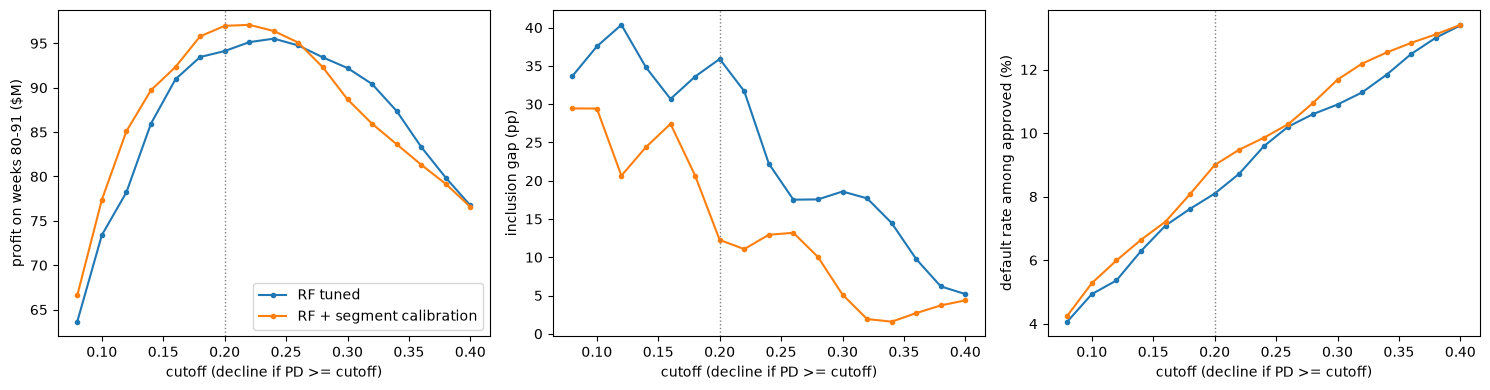

In [16]:
# How profit, inclusion gap and approved default rate change as the cutoff moves.

cutoffs = np.round(np.arange(0.08, 0.42, 0.02), 2)
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for name, p in [("RF tuned", p_rf), ("RF + segment calibration", p_rf_cal)]:
    rows = [evaluate(y_val, p, thin_val, cutoff=c) for c in cutoffs]
    axes[0].plot(cutoffs, [r["Profit $M"] for r in rows], marker="o", ms=3, label=name)
    axes[1].plot(cutoffs, [r["Gap@20% pp"] for r in rows], marker="o", ms=3, label=name)
    axes[2].plot(cutoffs, [r["Default % approved"] for r in rows], marker="o", ms=3, label=name)
for ax, ylab in zip(axes, ["profit on weeks 80-91 ($M)", "inclusion gap (pp)",
                           "default rate among approved (%)"]):
    ax.axvline(CUTOFF, color="grey", ls=":", lw=1)
    ax.set(xlabel="cutoff (decline if PD >= cutoff)", ylabel=ylab)
axes[0].legend(); plt.tight_layout(); plt.show()

### 11b. Stability week by week

A credit model has to hold up as time passes. AUC per validation week and segment:

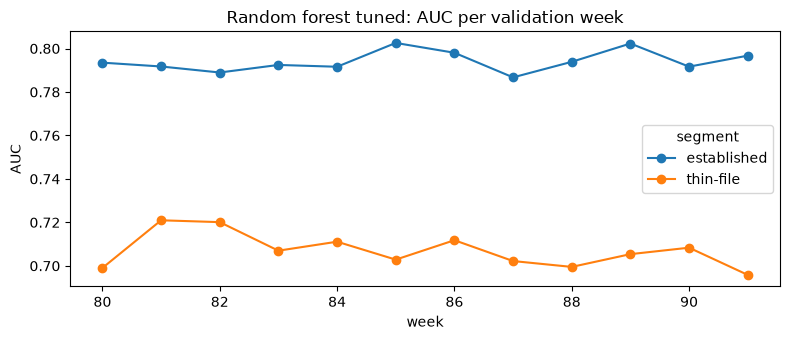

segment,established,thin-file
mean,0.7942,0.7070
std,0.0049,0.0080
min,0.7867,0.6958
max,0.8026,0.7210


In [17]:
# AUC for each validation week, to check the forest holds up over time.

weekly = []
for w in np.unique(week_val):
    m = week_val == w
    for seg, label in [(0, "established"), (1, "thin-file")]:
        s = m & (thin_val == seg)
        weekly.append({"week": w, "segment": label, "AUC": roc_auc_score(y_val[s], p_rf[s])})
weekly = pd.DataFrame(weekly).pivot(index="week", columns="segment", values="AUC")

ax = weekly.plot(marker="o", figsize=(8, 3.5), title="Random forest tuned: AUC per validation week")
ax.set_ylabel("AUC"); plt.tight_layout(); plt.show()
weekly.agg(["mean", "std", "min", "max"]).round(4)

### 11c. What the forest relies on, overall and per segment

- **Impurity importance:** how much each feature reduced impurity across all splits. Cheap, but biased
  toward high-cardinality features.
- **Permutation importance (per segment):** shuffle one feature and measure how much LogLoss worsens,
  computed separately for thin-file and established applicants. Slower but honest, and it answers the
  question that matters here: which features actually drive *thin-file* decisions.

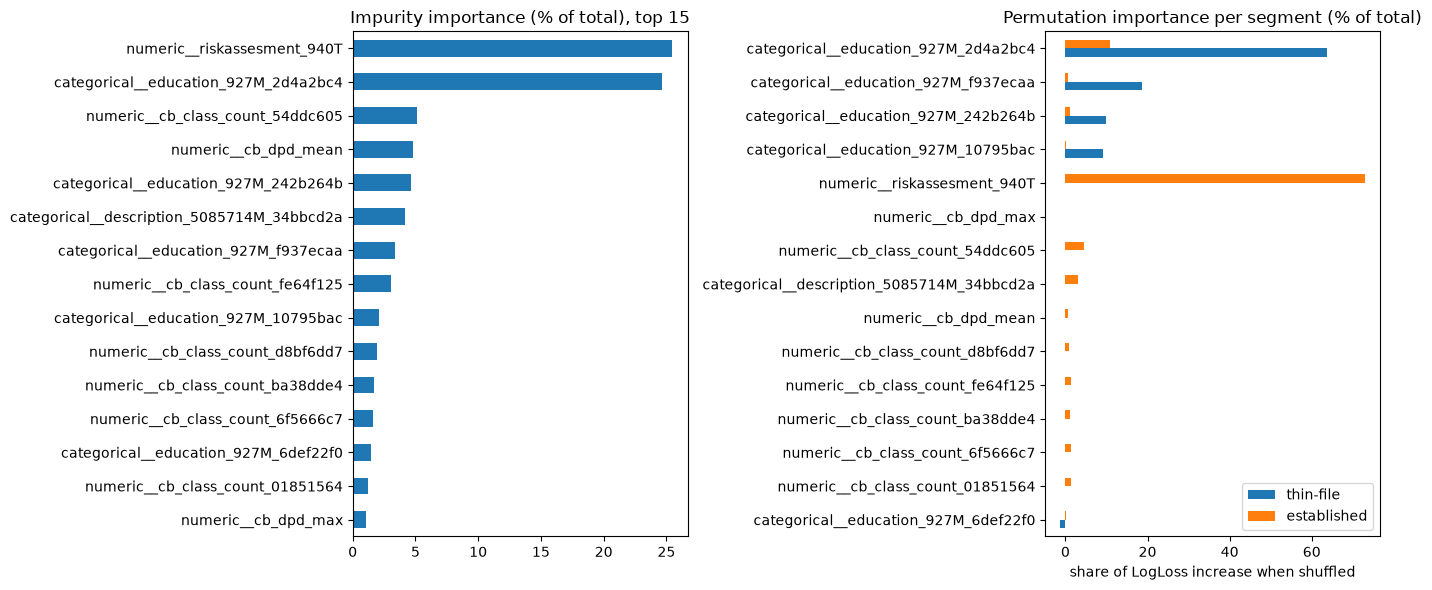

,thin-file,established
categorical__education_927M_2d4a2bc4,63.69,10.79
categorical__education_927M_f937ecaa,18.58,0.69
categorical__education_927M_242b264b,9.89,1.22
categorical__education_927M_10795bac,9.04,0.19
numeric__riskassesment_940T,0.00,72.91
numeric__cb_dpd_max,0.00,0.00
numeric__cb_class_count_54ddc605,0.00,4.61
categorical__description_5085714M_34bbcd2a,0.00,2.99
numeric__cb_dpd_mean,0.00,0.68
numeric__cb_class_count_d8bf6dd7,0.00,0.89


In [18]:
# Which features drive predictions: impurity (overall) and permutation (per segment).

imp = pd.Series(rf_final.feature_importances_, index=FEATURES)
imp = (imp / imp.sum() * 100).sort_values(ascending=False)

# Permutation importance on a sample, limited to the features that matter, to keep this affordable.
TOP_N, SAMPLE = 15, 20_000
top_features = imp.head(TOP_N).index.tolist()
rng_perm = np.random.default_rng(SEED)

perm = {}
for seg, label in [(1, "thin-file"), (0, "established")]:
    idx = np.flatnonzero(thin_val == seg)
    pick = rng_perm.choice(idx, size=min(SAMPLE, len(idx)), replace=False)
    Xs, ys = X_val.iloc[pick], y_val[pick]
    base = log_loss(ys, rf_final.predict_proba(Xs)[:, 1])
    scores = {}
    for f in top_features:
        Xp = Xs.copy()
        Xp[f] = rng_perm.permutation(Xp[f].values)
        scores[f] = log_loss(ys, rf_final.predict_proba(Xp)[:, 1]) - base
    perm[label] = pd.Series(scores)

perm_df = pd.DataFrame(perm)
perm_df = (perm_df / perm_df.sum() * 100).sort_values("thin-file", ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
imp.head(TOP_N)[::-1].plot.barh(ax=axes[0], title=f"Impurity importance (% of total), top {TOP_N}")
perm_df[::-1].plot.barh(ax=axes[1], title="Permutation importance per segment (% of total)")
axes[1].set_xlabel("share of LogLoss increase when shuffled")
plt.tight_layout(); plt.show()
perm_df.round(2)

**What to look for.** The LightGBM notebook found that `riskassesment_940T` and the `cb_*` features
have large effects **for thin-file applicants who do not have them at all** — the model learned that a
*missing* bureau score itself signals risk, so being thin-file is penalised through missingness even
though `thin_file` is not a feature. Notebook 05 imputed those columns and added missing-indicator
features, so check whether the same mechanism shows up here through the `*_missing` indicators. If it
does, that confirms the finding is a property of the data rather than of one algorithm.

## 12. Save artifacts for Task #4 and #14

| File | For |
|---|---|
| `best_params_randomforest.json` | chosen settings, tree count, selection rule, chosen half-life (#14 starts here) |
| `results_randomforest_valid_weeks_80_91.csv` | this notebook's comparison table (Task #4) |
| `results_all_models.csv` | random forest + boosting rows in one table, if lightgbm.ipynb has been run |
| `tuning_randomforest.csv` | every trial, for Skylar's tuning work |
| `predictions_valid_randomforest.parquet` | `case_id`, `thin_file`, PD from each variant, for the policy work |

Test predictions are **scores only** — `solution.csv` is never opened here.

In [19]:
# Save settings, tables and predictions so other tasks can reuse them.

rf_tuning.to_csv(ART / "tuning_randomforest.csv", index=False)

best_params = {
    "split": {"train_weeks": "0-67", "tune_weeks": "68-79", "valid_weeks": "80-91",
              "final_fit_weeks": "0-79"},
    "selection": f"lowest tune LogLoss; ties within {TIE_TOLERANCE} broken by largest min_samples_leaf",
    "randomforest": {
        "params": RF_PARAMS,
        "trees": FINAL_TREES,
        "search_trees": SEARCH_TREES,
        "n_trials": N_RF_TRIALS,
    },
    "recency_half_life_weeks": BEST_HL,
    "input_files": "model_ready_{fit,valid}.parquet (notebook 05: imputed, scaled, one-hot)",
    "excluded_from_features": NOT_FEATURES,
}
with open(ART / "best_params_randomforest.json", "w") as f:
    json.dump(best_params, f, indent=2, default=str)

pd.DataFrame({
    "case_id": val_case_id,
    "thin_file": thin_val,
    "WEEK_NUM": week_val,
    "pd_rf_tuned": p_rf,
    "pd_rf_calibrated": p_rf_cal,
    "pd_rf_recency": p_rf_rec,
    "pd_rf_recency_calibrated": p_rf_rec_cal,
}).to_parquet(ART / "predictions_valid_randomforest.parquet", index=False)

print("saved best_params_randomforest.json")
print("saved results_randomforest_valid_weeks_80_91.csv")
print("saved tuning_randomforest.csv")
print("saved predictions_valid_randomforest.parquet")
print(f"\npeak memory in use: {mem():.2f} GB")

saved best_params_randomforest.json
saved results_randomforest_valid_weeks_80_91.csv
saved tuning_randomforest.csv
saved predictions_valid_randomforest.parquet

peak memory in use: 1.55 GB


Findings

1. The forest matches boosting on ranking, and beats it once calibrated.

Tuned random forest hits 0.7679 AUC - the same number LightGBM's tuned model got.
With per-segment calibration it reaches 0.7706, slightly ahead. Logistic regression
is 0.7597. So on this data the bagging and boosting families land in the same place,
and the gap between model families is smaller than the gap between calibrated and
uncalibrated.

2. Calibration is worth far more than tuning.

Tuning moved AUC from 0.7657 to 0.7679 and actually widened the inclusion gap
slightly (34.3 to 35.9 pp). Per-segment calibration moved the gap from 36.8 to
12.3 pp and profit from $93.9M to $97.0M. Same model, same ranking - only the
probability level changed. That is where the money is.

3. The forest over-predicts thin-file risk, and calibration fixes it.

Before calibration the model predicts thin-file applicants are 7.1 pp riskier than
they turn out to be; established applicants are nearly exact at 0.12 pp. After
per-segment Platt scaling the thin-file error drops to 1.4 pp. The reliability curve
in section 8 shows it clearly: the orange line sits well below the diagonal before,
on it after.

The cause is the drift Krish quantified in notebook 07 - thin-file risk falls from
27.45% in weeks 0-67 to 19.81% in weeks 80-91, so a model trained on older weeks
carries a stale view of this segment.

4. Recency weighting works too, and picks the shortest half-life offered.

13 weeks won, same as LightGBM chose. On its own it takes the gap from 35.9 to
20.5 pp and profit to $96.3M. Combined with calibration it gives 12.3 pp and $96.8M -
essentially the same as calibration alone, so the two fixes address the same problem
and are not additive. Calibration alone is the simpler choice.

5. Probabilities are not compressed - the expected failure mode did not appear.

Predicted PD spans 0.002 to 0.833 against an actual default rate of 0.174, and the
histogram in section 7 is well spread rather than bunched at the base rate. Forests
often shrink predictions toward the middle because they average votes; with 200
trees and min_samples_leaf 258 this one does not. Brier 0.1228 is better than
logistic regression's 0.1241.

6. More trees stopped helping around 50.

Tune LogLoss goes 0.3977 at 10 trees to 0.3969 at 50, then 0.3968 at 200. AUC is
flat from 100 onward. 200 trees is comfortably past the plateau - #14 could cut this
to 100 and lose nothing while halving scoring time.

7. The model is stable week to week, and consistently worse on thin-file.

Across validation weeks 80-91, established AUC averages 0.7942 (sd 0.0049) and
thin-file 0.7070 (sd 0.0080), with no downward trend. The ranking holds; only the
probability level drifts, which is what calibration handles.

8. Missing bureau data is what penalises thin-file applicants.

Permutation importance per segment shows riskassesment_940T dominating for
established applicants but contributing almost nothing for thin-file ones - they do
not have it. The education_927M categories are the strongest features that every
applicant actually has. This matches notebook 06's finding that 22 of 51 features
are dead for this segment, and confirms the mechanism: dropping the thin_file column
does not make scoring neutral, because the model reads missingness itself as risk.

Recommendation for Task #4

Random forest is a credible candidate - it matches LightGBM on ranking and edges it
after calibration. But LightGBM trains in seconds where this takes 522 seconds for
one 200-tree model, and sklearn forests hold far more memory (this notebook needed
explicit deletion of each model to stay inside 8 GB). For equal accuracy, LightGBM
is the cheaper production choice.

The finding that matters more than the model choice: per-segment calibration cut the
inclusion gap by two-thirds and added ~$3M in profit on both families. Whichever
model Task #4 picks, it should be calibrated per segment.

Method note

The search space was capped at depth 14 with min_samples_leaf >= 200 for tractability
on a 2-core machine - fully grown trees took 22 minutes per trial against ~3 minutes
capped. Justified by the lightgbm notebook's finding that 28 of 30 settings tied
within 0.0003 LogLoss on this data. 6 trials, 1 tied within tolerance.